# 03 · Evaluation, calibration and the leakage comparison

[![Open In Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/github/Rishabh-bgp/brain-tumor-mri-classification/blob/main/notebooks/03_evaluation_and_calibration.ipynb)

Turns saved logits into the single prediction file (`results/predictions/*_test_predictions.csv`), fits temperature scaling and the *uncertain* threshold on validation, and derives every reported metric, table, figure and the web demo's statistics from that file.

*Rishabh Aryan · M.Tech (AI & Data Science), IIIT Bhagalpur. Research and education code, not a medical device.*

In [1]:
# --- Setup: works locally (repo checkout) and on Google Colab ---
import os, sys, subprocess
IN_COLAB = "google.colab" in sys.modules
if IN_COLAB:
    if not os.path.exists("brain-tumor-mri-classification"):
        subprocess.run(["git", "clone", "-q", "https://github.com/Rishabh-bgp/brain-tumor-mri-classification.git"], check=True)
    os.chdir("brain-tumor-mri-classification")
    subprocess.run([sys.executable, "-m", "pip", "install", "-q", "timm", "kagglehub", "imagehash", "captum",
                    "onnx", "onnxruntime", "scikit-image"], check=True)
elif os.path.basename(os.getcwd()) == "notebooks":
    os.chdir("..")
sys.path.insert(0, os.path.abspath("src"))
print("working directory:", os.getcwd())

working directory: /workspace/brain-tumor-mri/repo


In [2]:
import torch
print("PyTorch", torch.__version__, "| CUDA available:", torch.cuda.is_available())
if torch.cuda.is_available():
    print("GPU:", torch.cuda.get_device_name(0))
else:
    print("Running on CPU (Colab: Runtime > Change runtime type > GPU for faster training)")

PyTorch 2.15.0+cpu | CUDA available: False
Running on CPU (Colab: Runtime > Change runtime type > GPU for faster training)


In [3]:
subprocess.run([sys.executable, "scripts/make_predictions.py"], check=True)
subprocess.run([sys.executable, "scripts/make_report.py"], check=True)
import json, pandas as pd
cal = json.load(open("results/predictions/calibration.json"))
print(json.dumps(cal, indent=1))

clean {
 "temperature": 1.836449230211702,
 "val_ece_raw": 0.01121438311143354,
 "val_ece_calibrated": 0.0064790934169349,
 "uncertainty": {
  "conf_threshold": 0.67,
  "target_val_accuracy": 0.99,
  "val_retained_accuracy": 0.9908116385911179,
  "val_coverage": 0.9849170437405732,
  "rule": "smallest t in [0.50,0.99] (step 0.01) with val accuracy >= 0.99 on predictions with calibrated confidence >= t"
 },
 "val_accuracy": 0.9864253393665159
}
naive {
 "temperature": 1.7346503503040023,
 "val_ece_raw": 0.010562407458376766,
 "val_ece_calibrated": 0.016256220229184975,
 "uncertainty": {
  "conf_threshold": 0.5,
  "target_val_accuracy": 0.99,
  "val_retained_accuracy": 0.9904761904761905,
  "val_coverage": 1.0,
  "rule": "smallest t in [0.50,0.99] (step 0.01) with val accuracy >= 0.99 on predictions with calibrated confidence >= t"
 },
 "val_accuracy": 0.9904761904761905
}


{
 "clean": {
  "full_test": [
   0.93375,
   0.9332656025631204,
   1600
  ],
  "dedup_test": [
   0.9309576837416481,
   0.9257913308746009,
   1347
  ],
  "test_with_strict_train_dup": [
   0.9251700680272109,
   0.6521661477693826,
   441
  ],
  "test_without_linked_train_dup": [
   0.926530612244898,
   0.864120657835043,
   980
  ]
 },
 "naive": {
  "full_test": [
   0.96125,
   0.9605436442969923,
   1600
  ],
  "dedup_test": [
   0.9591685226429102,
   0.9587697863604535,
   1347
  ],
  "test_with_strict_train_dup": [
   0.9954648526077098,
   0.955188679245283,
   441
  ],
  "test_without_linked_train_dup": [
   0.9408163265306122,
   0.9075006035316738,
   980
  ]
 }
}
{
 "clean|glioma|dup": {
  "n": 9,
  "correct": 7,
  "accuracy": 0.7777777777777778
 },
 "naive|glioma|dup": {
  "n": 9,
  "correct": 7,
  "accuracy": 0.7777777777777778
 },
 "clean|glioma|nodup": {
  "n": 391,
  "correct": 329,
  "accuracy": 0.8414322250639387
 },
 "naive|glioma|nodup": {
  "n": 391,
  "correc

{
 "clean": {
  "temperature": 1.836449230211702,
  "val_ece_raw": 0.01121438311143354,
  "val_ece_calibrated": 0.0064790934169349,
  "uncertainty": {
   "conf_threshold": 0.67,
   "target_val_accuracy": 0.99,
   "val_retained_accuracy": 0.9908116385911179,
   "val_coverage": 0.9849170437405732,
   "rule": "smallest t in [0.50,0.99] (step 0.01) with val accuracy >= 0.99 on predictions with calibrated confidence >= t"
  },
  "val_accuracy": 0.9864253393665159
 },
 "naive": {
  "temperature": 1.7346503503040023,
  "val_ece_raw": 0.010562407458376766,
  "val_ece_calibrated": 0.016256220229184975,
  "uncertainty": {
   "conf_threshold": 0.5,
   "target_val_accuracy": 0.99,
   "val_retained_accuracy": 0.9904761904761905,
   "val_coverage": 1.0,
   "rule": "smallest t in [0.50,0.99] (step 0.01) with val accuracy >= 0.99 on predictions with calibrated confidence >= t"
  },
  "val_accuracy": 0.9904761904761905
 }
}


In [4]:
pred = pd.read_csv("results/predictions/clean_test_predictions.csv")
display(pred.head())
m = json.load(open("results/metrics.json"))
rows = []
for run in ("clean", "naive"):
    for k, v in m[run].items():
        rows.append({"model": run, "subset": k, "n": v["n"], "accuracy": v["accuracy"], "acc 95% CI": v["accuracy_ci95"],
                     "macro_F1": v["macro_f1"], "ROC-AUC": v.get("roc_auc_macro_ovr"), "ECE": v["ece_calibrated"]})
display(pd.DataFrame(rows).round(4))

,relpath,true,pred,p_glioma,p_meningioma,p_notumor,p_pituitary,raw_p_glioma,raw_p_meningioma,raw_p_notumor,raw_p_pituitary,confidence,norm_entropy,uncertain,test_has_train_dup_strict,test_has_train_dup,test_dedup_rep
0,Testing/glioma/Te-gl_1.jpg,glioma,glioma,0.999452,0.000426,0.000001,0.000121,0.999999,0.000001,0.000000,0.000000,0.999452,0.003576,False,False,False,True
1,Testing/glioma/Te-gl_10.jpg,glioma,glioma,1.000000,0.000000,0.000000,0.000000,1.000000,0.000000,0.000000,0.000000,1.000000,0.000000,False,False,True,True
2,Testing/glioma/Te-gl_100.jpg,glioma,glioma,1.000000,0.000000,0.000000,0.000000,1.000000,0.000000,0.000000,0.000000,1.000000,0.000000,False,False,False,True
3,Testing/glioma/Te-gl_101.jpg,glioma,glioma,0.958644,0.007961,0.000768,0.032628,0.997838,0.000151,0.000002,0.002009,0.958644,0.141488,False,False,False,True
4,Testing/glioma/Te-gl_102.jpg,glioma,notumor,0.052760,0.003210,0.919154,0.024875,0.005223,0.000031,0.993433,0.001313,0.919154,0.247439,False,False,False,True


,model,subset,n,accuracy,acc 95% CI,macro_F1,ROC-AUC,ECE
0,clean,full_test,1600,0.9338,"[0.92125, 0.945]",0.9333,0.9893,0.0363
1,clean,dedup_test,1347,0.9310,"[0.917595, 0.945063]",0.9258,0.9891,0.0378
2,clean,test_with_strict_train_dup,441,0.9252,"[0.90017, 0.952381]",0.6522,NaN,0.0436
3,clean,test_without_linked_train_dup,980,0.9265,"[0.908163, 0.942883]",0.8641,0.9910,0.0429
4,naive,full_test,1600,0.9612,"[0.951234, 0.970016]",0.9605,0.9908,0.0222
5,naive,dedup_test,1347,0.9592,"[0.948033, 0.970304]",0.9588,0.9896,0.0233
6,naive,test_with_strict_train_dup,441,0.9955,"[0.988662, 1.0]",0.9552,NaN,0.0053
7,naive,test_without_linked_train_dup,980,0.9408,"[0.92551, 0.953061]",0.9075,0.9874,0.0346


In [5]:
full = m["clean"]["full_test"]
display(pd.DataFrame(full["per_class"]).T.round(4))
print("confusion matrix (rows = true, cols = predicted; glioma, meningioma, notumor, pituitary):")
print(pd.DataFrame(full["confusion_matrix"], index=["glioma", "meningioma", "notumor", "pituitary"], columns=["glioma", "meningioma", "notumor", "pituitary"]))
print("uncertain rate:", round(full["uncertain_rate"], 4), "| accuracy confident:", full["accuracy_confident"], "| accuracy uncertain:", full["accuracy_uncertain"])

,precision,recall,f1,support
glioma,0.9970,0.8400,0.9118,400.0
meningioma,0.9373,0.8975,0.9170,400.0
notumor,0.8565,1.0000,0.9227,400.0
pituitary,0.9661,0.9975,0.9815,400.0


confusion matrix (rows = true, cols = predicted; glioma, meningioma, notumor, pituitary):
            glioma  meningioma  notumor  pituitary
glioma         336          23       39          2
meningioma       1         359       28         12
notumor          0           0      400          0
pituitary        0           1        0        399
uncertain rate: 0.0381 | accuracy confident: 0.9532163742690059 | accuracy uncertain: 0.4426229508196721


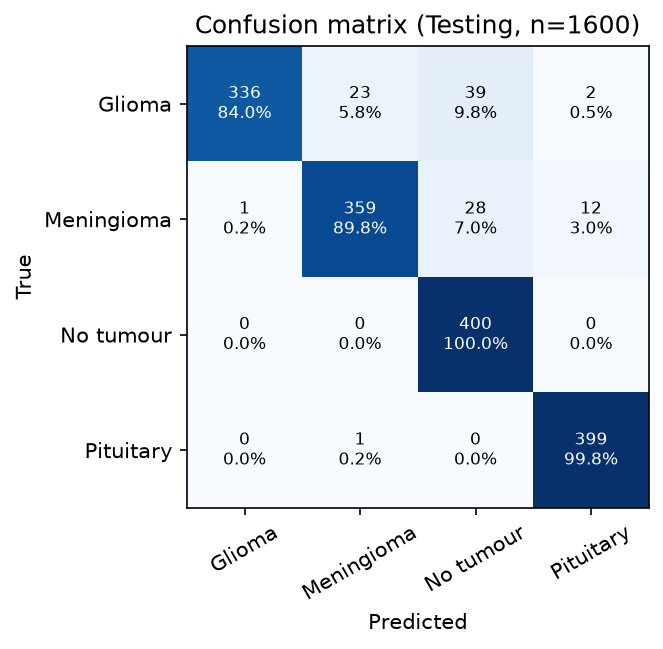

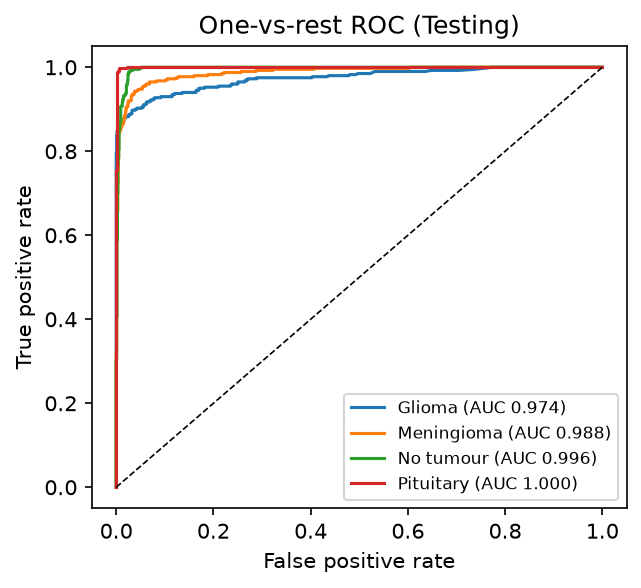

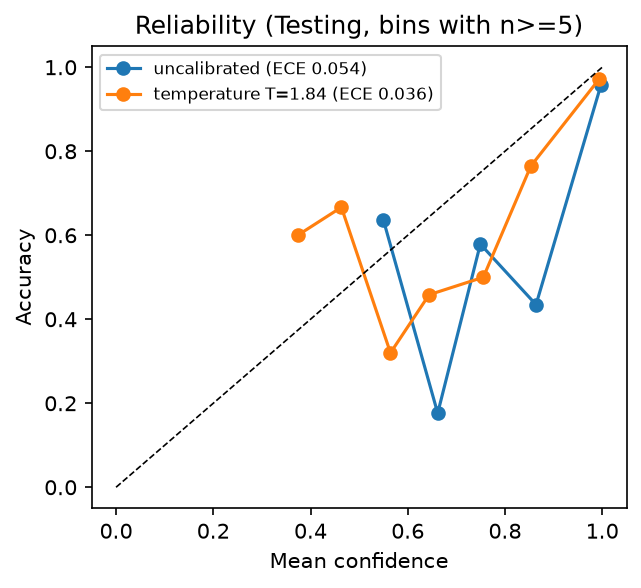

In [6]:
from IPython.display import Image, display
for f in ("confusion_matrix", "roc_curves", "reliability"):
    display(Image(f"results/figures/{f}.png", width=480))